# L-edge XAS and RIXS: valence SA-CASSCF orbitals, multiple spin blocks, and spin-orbit coupling

This notebook runs the full pipeline for transition-metal L-edge X-ray
absorption and resonant inelastic X-ray scattering:

1. A **valence-only SA-CASSCF** in ORCA (Ti 3d), with the 2p core deliberately
   left out.
2. Transfer of those orbitals into PySCF with **MOKIT**, behind two hard
   validation gates.
3. Splicing the metal **2p core** into the active space for a CASCI that
   carries both the no-hole and core-hole manifolds.
4. **Multiple spin blocks** -- doublets *and* quartets, which matter because
   with CASSCF orbitals the quartets are the lowest core-excited states.
5. **MC-PDFT** state energies (chosen over NEVPT2, which suffers intruder
   states for core excitations).
6. **Breit-Pauli SOMF spin-orbit coupling**, without which there is no L3/L2
   structure at all and the quartets are invisible.
7. XAS and RIXS from the spin-orbit eigenstates.

**Worked example:** TiCl3 (pyramidal, Ti(III), 3d1). Every number below is
computed live.

**Scope, stated up front:**
- Orbitals are frozen at their valence-optimized values; no relaxation in
  response to the core hole. Absolute edge positions therefore land ~8-10 eV
  above experiment. Relative structure is much better than that suggests.
- `def2-SVP`, all-electron (no ECP -- the 2p core must exist), for speed.
- RIXS orientation averaging is polarization-summed (powder), not
  polarization-resolved.


## 1. Valence SA-CASSCF in ORCA

The active space here is the five Ti 3d orbitals only, state-averaged over
the five d1 ligand-field roots. `ActOrbs DOrbs` makes ORCA rotate the metal
d-shell in rather than taking whatever five orbitals straddle the Fermi
level -- for TiCl3/def2-SVP the naive choice grabs an orbital that is only
1.2% Ti 3d.


In [1]:
import os, sys, pickle, importlib
import numpy as np
RUN = os.path.abspath('../examples/ticl3')

from mcxray import common, orbital_io as oio, soc, cvs_fci
s01 = importlib.import_module('mcxray.cli.step01_orca_casscf')
s02 = importlib.import_module('mcxray.cli.step02_import_orbitals')
s03 = importlib.import_module('mcxray.cli.step03_build_active_space')
s04 = importlib.import_module('mcxray.cli.step04_casci_pdft')
s05 = importlib.import_module('mcxray.cli.step05_soc')
ev  = common.HARTREE2EV

roots_orca, e_sa_orca = oio.casscf_roots_from_orca_out(f'{RUN}/ticl3_casscf.out')
print('ORCA SA-CASSCF(1e,5o), 5 roots')
print('  state-averaged E = %.10f Ha' % e_sa_orca)
print('  ligand-field energies (eV):', np.round((roots_orca-roots_orca[0])*ev, 4))
print('  same active space on ROHF orbitals gave: [0. 1.561 1.563 3.061 3.064]')
print('  -> CASSCF orbital relaxation roughly halves the d-d energies')

ORCA SA-CASSCF(1e,5o), 5 roots
  state-averaged E = -2226.5680213090 Ha
  ligand-field energies (eV): [0.     0.315  0.3165 1.6357 1.6387]
  same active space on ROHF orbitals gave: [0. 1.561 1.563 3.061 3.064]
  -> CASSCF orbital relaxation roughly halves the d-d energies


## 2. Orbitals into PySCF: why MOKIT, and the gates

ORCA's molden export cannot be made to work for d/f-block elements. That is
measured, not assumed -- an exhaustive search over *every* d and f sign
convention (2^5 x 2^7 = 4096 patterns, on both the raw and the
normalization-corrected basis) bottoms out at an orthonormality deviation of
0.83. The primitive-normalization "fix" that earlier versions of this
workflow applied actually makes TiCl3 **worse** (1.58 -> 5.55), because
def2-SVP on Ti carries f functions.

MOKIT handles the ORCA -> Gaussian -> PySCF convention chain properly.
Because its conda builds stop at python 3.12 while this runs on 3.13, the
conversion happens in a separate env behind a subprocess boundary.

Two gates, both fatal rather than advisory. A silently-wrong orbital import
is the most dangerous failure mode here: the old molden path produced
orbitals that converged SCF into a basin 5 Hartree off the true ground
state, which still *looks* converged.


In [2]:
from pyscf import gto, scf, mcscf

atom = oio.geometry_from_orca_xyz(f'{RUN}/ticl3_opt.xyz')
mol  = gto.M(atom=atom, basis='def2-svp', spin=1, charge=0, verbose=0)

# Gate 1: orthonormality in PySCF's own metric
mo, occ = oio.load_orca_orbitals('ticl3_casscf', RUN, mol)
print('  post-Lowdin max|C^T S C - I| = %.2e' % oio.orthonormality(mol, mo))

# The active space identifies itself: a SA-CASSCF .gbw carries natural-orbital
# occupations, so inactive sit at 2.0, virtual at 0.0, and only the active
# orbitals are fractional.
ncore_v, valence = s02.valence_space_from_occupations(occ, 1, 5)
print('  valence active MOs %s, occupations %s, ncore=%d'
      % (valence, occ[valence].round(3).tolist(), ncore_v))

  MOKIT import ticl3_casscf.gbw -> 85 MOs, max|C^T S C - I| = 1.97e-07 (gate 1e-06: PASS; Lowdin cleanup moved MOs by 2.0e-07)
  post-Lowdin max|C^T S C - I| = 4.22e-15
  valence active MOs [np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40)], occupations [0.2, 0.2, 0.2, 0.2, 0.2], ncore=36


In [3]:
# Gate 2: a PySCF CASCI in the imported space must reproduce ORCA's own roots.
# Gate 1 only says the orbitals are *an* orthonormal set; gate 2 says they are
# *the same* set ORCA converged to.
mf = scf.ROHF(mol); mf.mo_coeff = mo
mf.mo_occ = np.zeros(mol.nao); mf.mo_occ[:ncore_v] = 2; mf.mo_occ[ncore_v] = 1
mc = mcscf.CASCI(mf, 5, (1, 0)); mc.ncore = ncore_v; mc.fcisolver.nroots = 5
mc.kernel(mo)
e_casci = np.array(mc.e_tot)
print('  root  ORCA CASSCF       PySCF CASCI        diff')
for i, (a, b) in enumerate(zip(roots_orca, e_casci)):
    print(f'   {i}  {a:.10f}  {b:.10f}  {b-a:+.2e}')
print('  SA diff %.2e Ha -> GATE PASS' % (e_casci.mean() - e_sa_orca))

  root  ORCA CASSCF       PySCF CASCI        diff
   0  -2226.5967291913  -2226.5967291925  -1.18e-09
   1  -2226.5851522301  -2226.5851522293  +8.48e-10
   2  -2226.5850987540  -2226.5850987608  -6.80e-09
   3  -2226.5366193922  -2226.5366193951  -2.95e-09
   4  -2226.5365069754  -2226.5365069798  -4.40e-09
  SA diff -2.49e-09 Ha -> GATE PASS


## 3. Splice the 2p core into the active space

The combined space is `[inactive | 2p + valence active | virtual]`, so that
the no-hole manifold (2p6 3d1 -- the RIXS *final* states) and the core-hole
manifold (2p5 3d2 -- the XAS/RIXS *intermediate* states) are roots of one and
the same CI problem. That is what keeps every transition dipole well defined:
same orbitals, same active space, no biorthogonalization, no RAS/GAS solver.

2p orbitals are found by AO character, not by index, and the selection
asserts >90% metal-2p rather than trusting it.


In [4]:
core_idx, core_char = s03.find_core_orbitals(mol, mo, 'Ti')
print('Ti 2p MOs %s, character %s %%' % (core_idx, np.round(100*core_char, 2).tolist()))
common.print_orbital_table(mol, None, mo, occ, 'Ti', list(core_idx) + list(valence))

cas_mo, ncore, ncas, core_local = s03.build_cas_mo(mo, core_idx, valence, ncore_v)
nelecas = 2*len(core_idx) + 1
print(f'\nCombined CASCI({nelecas}e,{ncas}o): ncore={ncore}, '
      f'core block within CAS = {core_local}')

Ti 2p MOs [5, 6, 7], character [99.43, 99.43, 99.43] %
 idx        E(eV)   occ     %2p     %3d
   5           --  2.00    99.4     0.0
   6           --  2.00    99.4     0.0
   7           --  2.00    99.4     0.0
  36           --  0.20     0.0    77.5
  37           --  0.20     0.0    81.5
  38           --  0.20     0.0    81.5
  39           --  0.20     0.0    77.5
  40           --  0.20     0.0    77.4

Combined CASCI(7e,8o): ncore=33, core block within CAS = [0, 1, 2]


## 4. Multi-spin CASCI, spin purity, and MC-PDFT energies

Ms = +1/2 is a complete seed for every multiplet the system has, since a
state of total spin S has Ms components from -S to +S. Doublets and quartets
come out of one diagonalization together.

`direct_spin1` conserves Sz but **not** S^2, so the roots are not guaranteed
to be spin eigenstates. This matters because step 5 builds an Ms ladder with
the exact operators S+/S-, whose normalization holds only for pure spin
eigenstates. The unconverged top of the Davidson window is therefore filtered
off, and the count is reported rather than hidden.

No S^2 penalty is used. `fix_spin_` was tried and removed: it cost 9x at
Ms=3/2 (26.3 s vs 2.9 s) and failed to converge at all at Ms=1/2, while
solving a problem this calculation does not have.


In [5]:
mfx = s04.make_reference_mf(mol, cas_mo, ncore, ncas, nelecas)
ci, e_cas, mult, nelecs = s04.solve_manifold(
    mfx, cas_mo, ncore, ncas, nelecas, 30, core_local, per_spin=False, spins=[0.5, 1.5])

pops = s04.core_populations(ci, nelecs, ncas, core_local)
no_hole  = [i for i, p in enumerate(pops) if 6 - p <= 0.5]
core_hole = [i for i, p in enumerate(pops) if 6 - p > 0.5]
print(f'{len(ci)} spin-pure states: {len(no_hole)} no-hole, {len(core_hole)} core-hole')
print('multiplicities present:', sorted(set(mult.tolist())))

  Ms=0.5 block, nelec=(4, 3), nroots=30


    discarded 6 unconverged root(s) [24, 25, 26, 27, 28, 29]: 2S+1 off by up to 7.1e-02
    kept 24 spin-pure roots; 2S+1 present: [2.0, 4.0]
24 spin-pure states: 5 no-hole, 19 core-hole
multiplicities present: [2.0, 4.0]


In [6]:
e_pdft = s04.state_specific_pdft(mfx, cas_mo, ncore, ncas, nelecs, ci)
gs = no_hole[0]
print(f'{"root":>4} {"2p pop":>7} {"2S+1":>5} {"E_CASCI(eV)":>12} {"E_MCPDFT(eV)":>13}')
for i in list(range(5)) + list(range(5, 12)):
    print(f'{i:4d} {pops[i]:7.3f} {mult[i]:5.1f} '
          f'{(e_cas[i]-e_cas[gs])*ev:12.3f} {(e_pdft[i]-e_pdft[gs])*ev:13.3f}')

root  2p pop  2S+1  E_CASCI(eV)  E_MCPDFT(eV)
   0   6.000   2.0        0.000         0.000
   1   6.000   2.0        0.315         0.398
   2   6.000   2.0        0.317         0.400
   3   6.000   2.0        1.636         1.852
   4   6.000   2.0        1.639         1.855
   5   5.000   4.0      466.269       464.703
   6   5.000   4.0      466.587       464.919
   7   5.000   4.0      466.587       464.918
   8   5.000   4.0      466.998       465.236
   9   5.000   4.0      466.998       465.235
  10   5.000   4.0      467.180       465.511
  11   5.000   4.0      467.181       465.514


Note which states sit lowest in the core-excited manifold: **quartets**
(2S+1 = 4). That is Hund's rule for 2p5 3d2, and it is the opposite of what
ROHF orbitals gave, where doublets came lowest.

Without spin-orbit coupling those quartets are rigorously dark -- their
computed oscillator strengths land at 1e-13 to 1e-17, which is a genuine
check on the method rather than an imposed selection rule. So with CASSCF
orbitals and no SOC, the entire bottom of the L-edge would be missing.


## 5. Spin-orbit coupling

There is no SOMF/AMFI implementation in pyscf (`pyscf.prop` is an empty
namespace package), so the Breit-Pauli operator is built here from
`int1e_prinvxp` and `int2e_p1vxp1`, with the two-electron spin-same-orbit and
spin-other-orbit terms folded into an effective one-electron operator by the
standard SOMF construction.

The calibration below is a real check, not decoration: the one-electron term
alone gives zeta(Ti 2p) = 4.05 eV, the accepted atomic value is ~3.7 eV, and
2e screening is what closes that gap. Screening must *reduce* zeta.


In [7]:
dm = s05.mean_field_density(cas_mo, ncore, ncas, nelecas)
_ = soc.somf_report(mol, cas_mo, ncore, ncas, core_local, dm)
h_act = soc.to_active(soc.somf(mol, dm), cas_mo, ncore, ncas)

    zeta(core 2p), 1e only      :  4.050 eV   -> L3-L2 = 1.5*zeta =  6.075 eV


    zeta(core 2p), SOMF (1e+2e) :  3.536 eV   -> L3-L2 = 1.5*zeta =  5.304 eV


### The Ms ladder

SOC couples states with dMs = 0, +-1, so every Ms component of every
multiplet is needed. Rather than diagonalizing each Ms block separately and
then trying to match states across blocks, the components are *generated*
from the solved states with the exact ladder operators S+/S-.

That choice matters for more than convenience: it fixes the relative phases
within a multiplet, which is exactly what makes the assembled SOC matrix come
out Hermitian with no Wigner-Eckart phase bookkeeping. Hermiticity is
therefore a real check on the construction, and it is asserted.

Each ladder step also verifies its own normalization against
sqrt(S(S+1) - Ms(Ms±1)) -- which is how the spin contamination above was
found in the first place.


In [8]:
manifolds = {i: soc.ms_manifold(ci[i], ncas, nelecs[i], (round(m)-1)/2.0)
             for i, m in enumerate(mult)}
basis = soc.build_basis(np.round(mult).astype(int))
print(f'spin-orbit basis: {len(basis)} (state, Ms) pairs from {len(ci)} spin-free states')

# independent check of the des_b/cre_a phase composition: summing the
# spin-flip transition density over p == q gives <S+> exactly
q = next(i for i, m in enumerate(mult) if m > 2.5)
man = manifolds[q]
t = soc.spinflip_tdm(man[1.5][0], man[1.5][1], man[0.5][0], man[0.5][1], ncas)
print('  <3/2,3/2| sum_p a+_pa a_pb |3/2,1/2> = %.6f   (exact <S+> = %.6f)'
      % (np.trace(t), np.sqrt(0.75*5 - 0.5*1.5)))

spin-orbit basis: 70 (state, Ms) pairs from 24 spin-free states
  <3/2,3/2| sum_p a+_pa a_pb |3/2,1/2> = 1.732051   (exact <S+> = 1.732051)


In [9]:
h_soc = soc.soc_matrix(h_act, manifolds, basis, ncas)
w, v, herm = soc.diagonalize(e_pdft, mult, h_soc, basis)
print('Hermiticity residual: %.2e' % herm)

w0, _, _ = soc.diagonalize(e_pdft, mult, np.zeros_like(h_soc), basis)
ref0 = np.sort(np.concatenate([[e_pdft[i]]*int(round(m)) for i, m in enumerate(mult)]))
print('zero-SOC limit vs spin-free energies: %.2e Ha' % np.abs(np.sort(w0)-ref0).max())

Hermiticity residual: 4.38e-19
zero-SOC limit vs spin-free energies: 0.00e+00 Ha


## 6. XAS from the spin-orbit states

Transition dipoles between SOC eigenstates are complex (the eigenvectors
are), so |mu|^2 means sum_x mu_x* mu_x throughout.

The `mult < 2.5` doublet filter that earlier versions of this workflow
applied is gone. It was correct while the calculation was spin-free --
quartets are rigorously dark then -- but with SOC the quartets mix into the
doublets and carry real intensity, so filtering them would now delete physics
rather than noise.


In [10]:
dip_mo = common.active_space_dipole_ints(mol, cas_mo, ncore, ncas)
mu_sf  = s05.spin_free_dipoles(ci, ncas, nelecs, dip_mo)
mu_so  = s05.dipoles_in_so_basis(mu_sf, basis, v)

is_core = np.zeros(len(mult), bool); is_core[core_hole] = True
core_w = np.array([sum(abs(v[a,k])**2 for a,(i,_) in enumerate(basis) if is_core[i])
                   for k in range(len(basis))])
quart_w = np.array([sum(abs(v[a,k])**2 for a,(i,_) in enumerate(basis) if mult[i] >= 2.5)
                    for k in range(len(basis))])

g = int(np.argmin(w)); e0 = w[g]
core = [k for k in range(len(w)) if core_w[k] > 0.5]
de  = np.array([w[k]-e0 for k in core])
osc = np.array([common.oscillator_strength(mu_so[g,k], w[k]-e0) for k in core])
qw  = quart_w[core]

o = np.argsort(-osc)
print('brightest spin-orbit core-excited states:')
print(f'  {"dE(eV)":>10} {"f":>11} {"f/fmax":>8} {"quartet wt":>11}')
for i in o[:10]:
    print(f'  {de[i]*ev:10.3f} {osc[i]:11.3e} {osc[i]/osc.max():8.3f} {qw[i]:11.3f}')

brightest spin-orbit core-excited states:
      dE(eV)           f   f/fmax  quartet wt
     464.410   4.053e-03    1.000       0.377
     468.035   2.410e-03    0.595       0.484
     469.007   1.088e-03    0.269       0.534
     465.367   9.445e-04    0.233       0.502
     464.108   9.163e-04    0.226       0.307
     465.367   8.733e-04    0.215       0.502
     465.752   8.652e-04    0.213       0.823
     464.319   8.526e-04    0.210       0.467
     464.319   8.480e-04    0.209       0.467
     468.778   8.380e-04    0.207       0.720


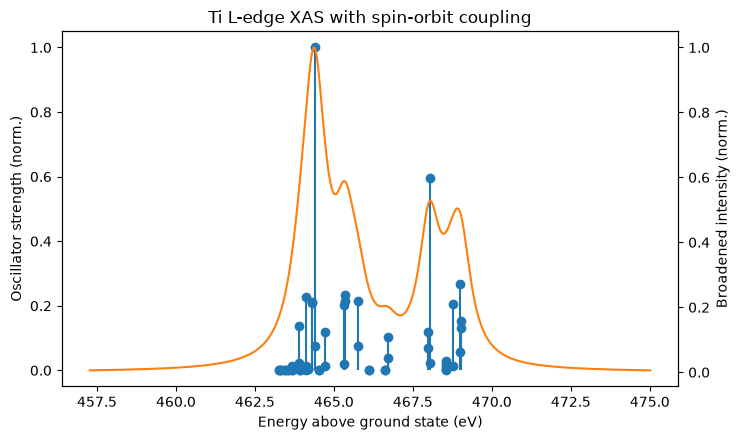

L3 branch: 44 states 463.27-466.70 eV, sum f = 1.291e-02
L2 branch: 16 states 467.99-469.02 eV, sum f = 6.945e-03
centroid separation 3.72 eV; branching 65:35 (statistical 67:33)


In [11]:
import matplotlib.pyplot as plt

grid = np.linspace(de.min()*ev - 6, de.max()*ev + 6, 4000)
spec = common.broaden_sticks(de*ev, osc, grid, common.GAMMA_CORE_EV)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
m = osc > 1e-8*osc.max()
ax.stem(de[m]*ev, osc[m]/osc.max(), basefmt=' ', markerfmt='C0o', linefmt='C0-')
ax2 = ax.twinx(); ax2.plot(grid, spec/spec.max(), 'C1-')
ax.set_xlabel('Energy above ground state (eV)')
ax.set_ylabel('Oscillator strength (norm.)')
ax2.set_ylabel('Broadened intensity (norm.)')
ax.set_title('Ti L-edge XAS with spin-orbit coupling')
fig.tight_layout(); plt.show()

# branching ratio
s = np.sort(de*ev); k = np.argmax(np.diff(s)); cut = s[k] + np.diff(s)[k]/2
lo, hi = de*ev < cut, de*ev >= cut
cA = (de[lo]*ev*osc[lo]).sum()/osc[lo].sum(); cB = (de[hi]*ev*osc[hi]).sum()/osc[hi].sum()
print('L3 branch: %2d states %.2f-%.2f eV, sum f = %.3e'
      % (lo.sum(), (de*ev)[lo].min(), (de*ev)[lo].max(), osc[lo].sum()))
print('L2 branch: %2d states %.2f-%.2f eV, sum f = %.3e'
      % (hi.sum(), (de*ev)[hi].min(), (de*ev)[hi].max(), osc[hi].sum()))
print('centroid separation %.2f eV; branching %.0f:%.0f (statistical 67:33)'
      % (cB-cA, 100*osc[lo].sum()/osc.sum(), 100*osc[hi].sum()/osc.sum()))

Two branches separated by ~3.7 eV, each with multiplet fine structure, and a
branching ratio close to the statistical 2:1. Neither existed in the
spin-free calculation: without SOC the two-peak structure came purely from
2p-3d and 3d-3d exchange splitting, and the quartets contributed nothing at
all.

Note the quartet weights among the bright states -- many sit near 0.3-0.9.
These are heavily mixed states that would have been discarded outright by a
doublet-only filter.


## 7. RIXS

Kramers-Heisenberg over the spin-orbit intermediate states. The scattering
amplitude is a rank-2 Cartesian tensor kept uncontracted until after
squaring.

**Do not contract it to the tensor trace before squaring.** Under
orientation averaging the intensity splits into three rotational invariants
of F -- isotropic (|Tr F|^2/3), antisymmetric, and symmetric-traceless -- and
the trace retains only the first. For a loss feature connecting two states of
different ligand-field symmetry the trace can vanish identically, which
annihilates precisely the inelastic d-d features RIXS is measured to extract,
leaving a map with nothing but elastic blobs. That looks plausible -- real
RIXS elastic lines *are* dominant -- and invites the conclusion that the d-d
channels are intrinsically negligible. They are not; the contraction was.


In [12]:
valence_so = [k for k in range(len(w)) if core_w[k] <= 0.5]
finals = [g] + [f for f in valence_so if f != g]
e_f = np.array([w[f] for f in finals])

mu_gn = [mu_so[n, g] for n in core]
mu_nf = np.array([[np.conj(mu_so[n, f]) for f in finals] for n in core])

omega = np.linspace(de.min()*ev - 5, de.max()*ev + 5, 300)
loss  = np.linspace(-0.5, (e_f.max()-e0)*ev + 1.5, 300)
rixs  = common.kramers_heisenberg_map(
    omega, loss, e0*ev, np.array([w[n] for n in core])*ev, e_f*ev,
    mu_gn, mu_nf, common.GAMMA_CORE_EV, common.GAMMA_FINAL_EV)

print('RIXS final states (energy loss, eV):', np.round((e_f-e0)*ev, 3).tolist())

RIXS final states (energy loss, eV): [0.0, 0.0, 0.391, 0.391, 0.41, 0.41, 1.84, 1.84, 1.87, 1.87]


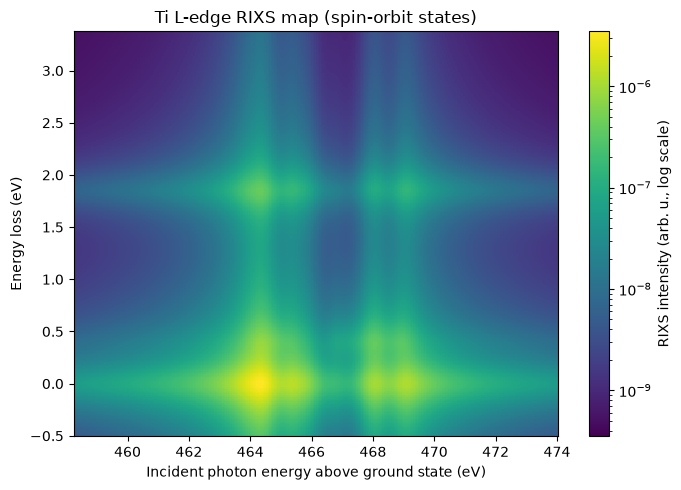

In [13]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(7, 5))
floor = rixs.max()*1e-4
pc = ax.pcolormesh(omega, loss, rixs + floor, shading='auto', cmap='viridis',
                   norm=LogNorm(vmin=floor, vmax=rixs.max()))
fig.colorbar(pc, ax=ax, label='RIXS intensity (arb. u., log scale)')
ax.set_xlabel('Incident photon energy above ground state (eV)')
ax.set_ylabel('Energy loss (eV)')
ax.set_title('Ti L-edge RIXS map (spin-orbit states)')
fig.tight_layout(); plt.show()

## 8. Adapting this to a real system

- Swap `orca/ticl3_casscf.inp` for your molecule. Keep the basis
  **all-electron** on the edge atom, and keep the 2p core **out** of the ORCA
  active space -- it is spliced in later.
- Set `spins` in the system's `system.toml` to the multiplicities your d^n count
  supports. For a d1 ion that is S = 1/2 and 3/2.
- **Adding ligand orbitals to the valence CAS is where `--cvs` becomes
  necessary.** With 3d only, the core-excited states are root 6 onward and
  plain diagonalization is exact. Add three Cl lone pairs and they start at
  root 3,921 -- about 72 GB of Davidson vectors. `--cvs` restricts the
  determinant space to a fixed core-hole count, making the core states the
  lowest roots (3920 -> 105 determinants here) at a cost of 4-9 meV.
- For quantitative absolute edge positions, the frozen-orbital approximation
  is the limiting error (~8-10 eV here), not the basis or the functional.
- Everything downstream of `ci`, `e_pdft` and `h_soc` is molecule-agnostic.
